# VIBES rank and tau: how far fixed-model EC moves (16 Nov 2026)

Every network scan saved under the 87-blank background was refitted to convergence at ranks 10, 20, 40 and 70 and
tau 0.05, 0.1 and 0.2 by `workflows/run_vibes_rank_tau_ec_20261116.py`. EC is read with the frozen k 4 IMPROVE model,
which was trained on spectra corrected at rank 70 and tau 0.1. Nothing is refitted here.

**What this can and cannot show.** A change in EC here is the cost of correcting a spectrum one way and calibrating
another way. It does not say which setting gives the best EC. That needs the calibration refitted at each setting.
EC is in µg per filter; the bundle has no sampled volumes.

**What it shows** (4,376 scans, all certified at all 12 settings; 3,626 are PM2.5).

- **Rank 40 gives the same EC as rank 70.** Median change 0.01 %, largest 0.03 µg.
- **Rank 20 is close, rank 10 is not.** Rank 20 moves EC by a median 0.5 %. Rank 10 moves it by 3 %, and 17 % of scans move by more than 10 %.
- **tau moves every scan a little.** Median 1.2 % at tau 0.05 and 2.0 % at tau 0.2; 3 % and 6 % of scans move by more than 10 %.
- **For scale, the solver switch** moves the median scan by 0.003 %, and the 97 early stops by a median 5 %.
- **Neither check that needs no calibration picks another setting.** Repeat scans agree about as well at every setting.
  Field blanks are tightest at rank 70 and spread out as the rank falls.
- **The fitted noise level follows tau.** Its median roughly doubles each time tau doubles, so a noise level is only
  comparable between fits made at one tau.
- **With the calibration rebuilt at each tau (section 7), no tau is better at every k.** tau 0.1 stays.
- **One QC-failed training spectrum moves SPARTAN EC from the k 4 model by a median 17 % (section 8),** while IMPROVE
  scores stay the same.
- **Training without the heaviest filters steadies the model but does not pin EC down (section 9):** the cut-off moves
  EC by 3 to 30 %, and about 7 % of spread is left when IMPROVE sites are resampled.

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
AREA = Path(os.environ.get("AETH_AREA", "."))
R = AREA / "output/tables/vibes_rank_tau_ec_20261116"
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#3a3a38"
plt.rcParams.update({"figure.dpi": 130, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9a9a95", "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.grid": True, "grid.color": "#e8e8e4", "grid.linewidth": .6, "lines.linewidth": 1.2})
pd.set_option("display.width", 220, "display.max_columns", 30)

scans = pd.read_csv(R / "scans.csv", dtype={"analysis_id": str})
fits = {}
for f in sorted(R.glob("fit_rank*_tau*.npz")):
    z = np.load(f)
    fits[(int(z["rank"]), float(z["tau"]))] = {k: z[k] for k in z.files}
REF = (70, 0.1)
ref = fits[REF]
pm = scans.filter_type.eq("PM2.5").to_numpy()
blank = scans.filter_type.eq("FB").to_numpy()
addis = pm & scans.code.eq("ETAD").to_numpy()
early = scans.premature_stop.to_numpy(bool)
print(len(scans), "scans:", int(pm.sum()), "PM2.5,", int(addis.sum()), "of them Addis,", int(blank.sum()), "field blanks")
pd.DataFrame([{"rank": k[0], "tau": k[1], "certified": int(f["ok"].sum()), "of": len(f["ok"])} for k, f in sorted(fits.items(), reverse=True)])

4376 scans: 3626 PM2.5, 274 of them Addis, 535 field blanks


,rank,tau,certified,of
0,70,0.20,4376,4376
1,70,0.10,4376,4376
2,70,0.05,4376,4376
3,40,0.20,4376,4376
4,40,0.10,4376,4376
5,40,0.05,4376,4376
6,20,0.20,4376,4376
7,20,0.10,4376,4376
8,20,0.05,4376,4376
9,10,0.20,4376,4376


## 1. PM2.5 scans against the network setting (rank 70, tau 0.1)

Percent changes use scans whose EC at the network setting is at least 1 µg, so a near-zero EC does not set the scale.
The slope and intercept are an ordinary fit of EC at the setting on EC at the network setting.

In [2]:
def compare(key, mask):
    f = fits[key]
    m = mask & f["ok"] & ref["ok"]
    base, d = ref["ec"][m], f["ec"][m] - ref["ec"][m]
    loaded = base >= 1
    slope, intercept = np.polyfit(base, f["ec"][m], 1)
    return {"rank": key[0], "tau": key[1], "scans": int(m.sum()),
            "median change (µg)": np.median(d), "median |change| (µg)": np.median(np.abs(d)),
            "95th pct |change| (µg)": np.quantile(np.abs(d), .95), "largest |change| (µg)": np.abs(d).max(),
            "median |change| (%)": 100 * np.median(np.abs(d[loaded]) / base[loaded]),
            "moved > 10 % (share)": 100 * np.mean(np.abs(d[loaded]) / base[loaded] > .1),
            "slope": slope, "intercept (µg)": intercept, "r": np.corrcoef(base, f["ec"][m])[0, 1],
            "baseline change (% of corrected RMS)": 100 * np.median(f["baseline_change_rms"][m] / ref["corrected_rms"][m])}

keys = sorted(fits, key=lambda k: (-k[0], abs(k[1] - 0.1), k[1]))
print("Median EC at the network setting:", round(float(np.median(ref["ec"][pm & ref["ok"]])), 2), "µg per filter")
network = pd.DataFrame([compare(k, pm) for k in keys if k != REF]).round(3)
network

Median EC at the network setting: 3.76 µg per filter


,rank,tau,scans,median change (µg),median |change| (µg),95th pct |change| (µg),largest |change| (µg),median |change| (%),moved > 10 % (share),slope,intercept (µg),r,baseline change (% of corrected RMS)
0,70,0.05,3626,0.004,0.048,0.619,14.364,1.172,3.253,0.988,0.071,0.997,3.768
1,70,0.20,3626,-0.001,0.084,0.942,3.922,2.030,5.997,1.000,0.057,0.998,7.642
2,40,0.10,3626,0.000,0.000,0.005,0.030,0.011,0.000,1.000,0.000,1.000,0.019
3,40,0.05,3626,0.005,0.049,0.618,14.364,1.202,3.253,0.988,0.071,0.997,3.875
4,40,0.20,3626,-0.000,0.084,0.943,3.922,2.013,6.025,1.000,0.057,0.998,7.586
5,20,0.10,3626,0.016,0.020,0.152,0.519,0.487,3.508,0.998,0.041,1.000,1.068
6,20,0.05,3626,0.030,0.083,0.644,14.364,1.918,7.412,0.988,0.108,0.997,5.854
7,20,0.20,3626,0.053,0.098,0.937,3.920,2.447,7.723,0.998,0.103,0.998,8.056
8,10,0.10,3626,0.012,0.131,0.478,1.795,2.956,17.454,1.002,0.035,0.999,10.342
9,10,0.05,3626,0.011,0.220,0.909,14.367,4.793,23.734,0.994,0.068,0.996,15.019


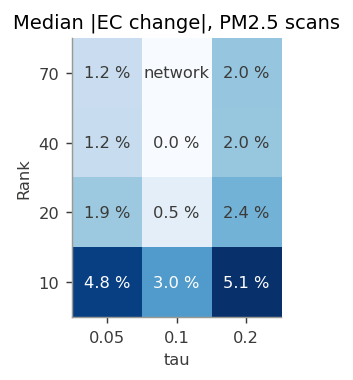

In [3]:
grid = network.pivot(index="rank", columns="tau", values="median |change| (%)").reindex([70, 40, 20, 10])
grid.loc[70, 0.1] = 0.0
grid = grid[sorted(grid.columns)]
fig, ax = plt.subplots(figsize=(3.6, 3.0))
im = ax.imshow(grid.to_numpy(), cmap="Blues", vmin=0)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.to_numpy()[i, j]
        ax.text(j, i, "network" if (grid.index[i], grid.columns[j]) == REF else f"{v:.1f} %", ha="center", va="center",
                color="white" if v > grid.to_numpy().max() * .55 else INK)
ax.set_xticks(range(grid.shape[1]), [f"{t:g}" for t in grid.columns]); ax.set_yticks(range(grid.shape[0]), grid.index)
ax.set(xlabel="tau", ylabel="Rank", title="Median |EC change|, PM2.5 scans"); ax.grid(False)
fig.tight_layout(); plt.show()

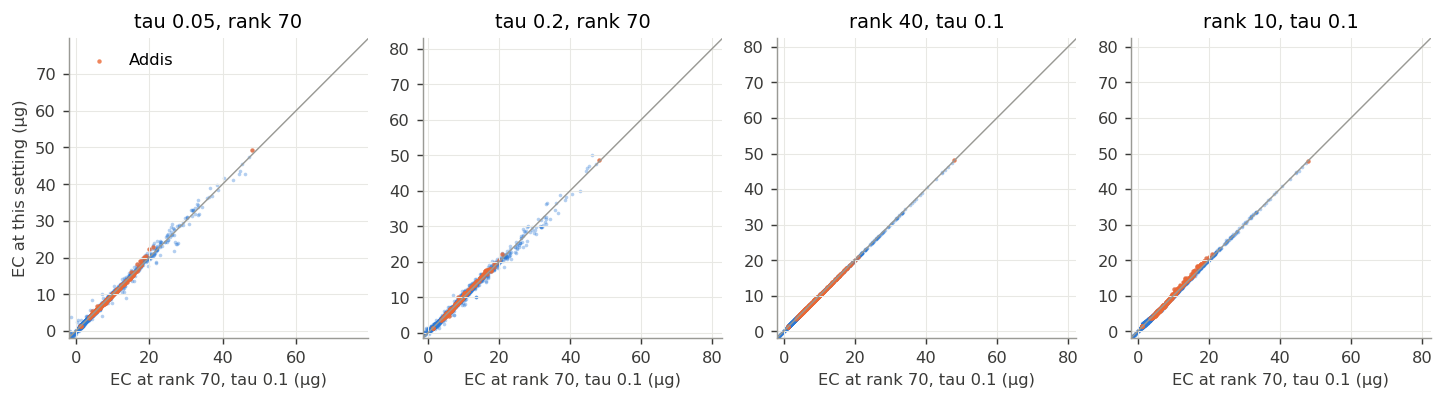

In [4]:
panels = [((70, 0.05), "tau 0.05, rank 70"), ((70, 0.2), "tau 0.2, rank 70"), ((40, 0.1), "rank 40, tau 0.1"), ((10, 0.1), "rank 10, tau 0.1")]
fig, axes = plt.subplots(1, 4, figsize=(11.2, 3.1))
for ax, (key, title) in zip(axes, panels):
    m = pm & fits[key]["ok"] & ref["ok"]
    x, y = ref["ec"][m], fits[key]["ec"][m]
    lo, hi = np.quantile(np.r_[x, y], [.001, .999])
    ax.plot([lo, hi], [lo, hi], color="#9a9a95", lw=.8)
    ax.scatter(x, y, s=4, color=BLUE, alpha=.35, linewidth=0)
    a_ = addis[m]
    ax.scatter(x[a_], y[a_], s=6, color=ORANGE, alpha=.8, linewidth=0, label="Addis")
    ax.set(xlim=(lo, hi), ylim=(lo, hi), title=title, xlabel="EC at rank 70, tau 0.1 (µg)")
    ax.set_box_aspect(1)
axes[0].set_ylabel("EC at this setting (µg)"); axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

## 2. Addis PM2.5 scans

In [5]:
pd.DataFrame([compare(k, addis) for k in keys if k != REF]).round(3)

,rank,tau,scans,median change (µg),median |change| (µg),95th pct |change| (µg),largest |change| (µg),median |change| (%),moved > 10 % (share),slope,intercept (µg),r,baseline change (% of corrected RMS)
0,70,0.05,274,-0.025,0.075,0.494,2.223,0.952,1.095,1.025,-0.210,0.998,6.270
1,70,0.20,274,0.143,0.169,0.896,1.649,2.290,1.095,1.049,-0.196,0.998,9.769
2,40,0.10,274,-0.000,0.000,0.002,0.010,0.004,0.000,1.000,0.000,1.000,0.013
3,40,0.05,274,-0.027,0.075,0.494,2.223,0.976,1.095,1.025,-0.210,0.998,6.274
4,40,0.20,274,0.144,0.169,0.896,1.650,2.281,1.095,1.049,-0.195,0.998,9.769
5,20,0.10,274,0.010,0.015,0.078,0.158,0.182,0.000,0.998,0.038,1.000,0.756
6,20,0.05,274,-0.017,0.099,0.500,2.228,1.271,1.460,1.023,-0.171,0.997,7.318
7,20,0.20,274,0.153,0.176,0.908,1.656,2.230,1.095,1.047,-0.160,0.998,9.699
8,10,0.10,274,-0.019,0.248,1.135,1.795,3.412,2.920,1.068,-0.477,0.997,22.571
9,10,0.05,274,-0.090,0.338,1.827,3.340,4.695,16.423,1.118,-0.950,0.993,31.003


## 3. Field blanks

A field blank carries no deposit, so its EC should be near zero at any setting. The spread is the more useful number:
the fixed model's intercept belongs to rank 70 and tau 0.1.

In [6]:
def blanks(key):
    f = fits[key]
    v = f["ec"][blank & f["ok"]]
    return {"rank": key[0], "tau": key[1], "blank scans": len(v), "median EC (µg)": np.median(v),
            "interquartile range (µg)": np.subtract(*np.quantile(v, [.75, .25])), "5th pct": np.quantile(v, .05), "95th pct": np.quantile(v, .95)}
pd.DataFrame([blanks(k) for k in keys]).round(3)

,rank,tau,blank scans,median EC (µg),interquartile range (µg),5th pct,95th pct
0,70,0.10,535,1.268,0.003,1.264,1.278
1,70,0.05,535,1.269,0.003,1.262,1.280
2,70,0.20,535,1.269,0.002,1.266,1.275
3,40,0.10,535,1.270,0.006,1.264,1.285
4,40,0.05,535,1.271,0.008,1.263,1.288
5,40,0.20,535,1.270,0.004,1.266,1.280
6,20,0.10,535,1.269,0.022,1.244,1.318
7,20,0.05,535,1.270,0.026,1.237,1.321
8,20,0.20,535,1.270,0.019,1.249,1.316
9,10,0.10,535,1.296,0.080,1.207,1.438


## 4. Repeat scans of one filter

Filters with two or more PM2.5 scans, first two scans. If one setting were clearly better, repeat scans should agree
more closely there. The table leaves out the 12 filters the lab review marks as having one weak scan
(`gallery/app/src/lib/nativeScanReview.ts`).

In [7]:
REVIEWED = {"CHTS-0777-8", "CHTS-0814-5", "CHTS-0830-5", "ETAD-0037-5", "ETAD-0139-3", "INDH-0209-1", "INDH-0265-1",
            "KRSE-0136-8", "PRFJ-0073-1", "ZAJB-0121-1", "ZAJB-0283-3", "ZAJB-0286-6"}
index = scans[pm & ~scans.filter_id.isin(REVIEWED)].groupby("filter_id").indices
pairs = np.array([scans.index[pm & ~scans.filter_id.isin(REVIEWED)][v[:2]] for v in index.values() if len(v) >= 2])
def repeats(key):
    f = fits[key]
    ok = f["ok"][pairs].all(1)
    a, b = f["ec"][pairs[ok, 0]], f["ec"][pairs[ok, 1]]
    return {"rank": key[0], "tau": key[1], "filters": int(ok.sum()), "median |scan 1 - scan 2| (µg)": np.median(np.abs(a - b)),
            "90th pct (µg)": np.quantile(np.abs(a - b), .9), "r": np.corrcoef(a, b)[0, 1]}
pd.DataFrame([repeats(k) for k in keys]).round(3)

,rank,tau,filters,median |scan 1 - scan 2| (µg),90th pct (µg),r
0,70,0.10,148,0.052,0.502,0.970
1,70,0.05,148,0.066,0.480,0.967
2,70,0.20,148,0.051,0.349,0.970
3,40,0.10,148,0.052,0.502,0.970
4,40,0.05,148,0.066,0.480,0.967
5,40,0.20,148,0.051,0.349,0.970
6,20,0.10,148,0.055,0.499,0.970
7,20,0.05,148,0.065,0.523,0.967
8,20,0.20,148,0.052,0.350,0.970
9,10,0.10,148,0.056,0.556,0.972


## 5. Where the corrected spectrum moves

Mean corrected absorbance in three windows, median over PM2.5 scans. The 2000-2500 cm⁻¹ window has no aerosol bands,
so its level shows how far above the baseline the spectrum is left to sit.

In [8]:
names = [n for n in ref if n.startswith("mean ")]
def levels(key):
    f = fits[key]
    m = pm & f["ok"]
    return {"rank": key[0], "tau": key[1], **{n[5:] + " (×1e-3)": 1e3 * np.median(f[n][m]) for n in names},
            "noise level, median (×1e-4)": 1e4 * np.median(f["sigma"][m])}
pd.DataFrame([levels(k) for k in keys]).round(3)

,rank,tau,featureless 2000-2500 (×1e-3),C-H 2800-3000 (×1e-3),carbonyl 1650-1800 (×1e-3),"noise level, median (×1e-4)"
0,70,0.10,0.260,10.347,5.052,6.122
1,70,0.05,0.336,10.502,5.243,3.103
2,70,0.20,0.103,9.932,4.731,11.810
3,40,0.10,0.260,10.347,5.053,6.122
4,40,0.05,0.337,10.502,5.242,3.103
5,40,0.20,0.106,9.933,4.732,11.811
6,20,0.10,0.299,10.483,5.091,6.189
7,20,0.05,0.378,10.596,5.279,3.138
8,20,0.20,0.115,10.028,4.792,11.918
9,10,0.10,0.328,12.024,5.261,6.687


## 6. Early stops of the October run, for scale
The same comparison for the solver switch itself: October baseline against converged, both at rank 70 and tau 0.1.

In [9]:
d = pd.read_csv(AREA / "output/tables/network_baselines_v2_20261103/vibes_fit_diagnostics.csv")
d = d[d.vibes_model.eq("b87") & d.filter_type.eq("PM2.5")]
ch = (d.ec_newton_baseline_frozen_model_ug - d.ec_saved_baseline_frozen_model_ug)
loaded = d.ec_saved_baseline_frozen_model_ug >= 1
pd.DataFrame([{"group": name, "scans": int(m.sum()), "median |change| (µg)": ch[m].abs().median(),
               "median |change| (%)": 100 * (ch[m & loaded].abs() / d.ec_saved_baseline_frozen_model_ug[m & loaded]).median(),
               "largest |change| (µg)": ch[m].abs().max()}
              for name, m in [("All PM2.5", d.premature_stop | True), ("Not an early stop", ~d.premature_stop), ("Early stop", d.premature_stop),
                              ("Addis early stop", d.premature_stop & d.code.eq("ETAD"))]]).round(4)

,group,scans,median |change| (µg),median |change| (%),largest |change| (µg)
0,All PM2.5,3626,0.0001,0.0027,2.4479
1,Not an early stop,3529,0.0001,0.0025,0.0859
2,Early stop,97,0.1750,5.0923,2.4479
3,Addis early stop,10,0.8201,11.4353,2.4479


## 7. Which tau is best once the calibration matches it

Sections 1 to 6 read EC with a model trained at tau 0.1. Here the IMPROVE calibration is rebuilt at each tau
(`workflows/run_vibes_tau_calibration_20261116.py`, rank 70, 12,393 IMPROVE and 233 Addis spectra, all certified), so each
tau is scored with its own model. At tau 0.1 the rebuild returns the 3 Nov calibration: k 4, test RMSE 3.850.

**What it shows.**

- **No tau wins at every k.** Scores are compared at fixed k, with sites resampled to see which gaps are larger than chance.
- **tau 0.05 is never better than tau 0.1.** It is worse in 3 of 12 comparisons and no different in the other 9.
- **tau 0.2 is better at low k and worse at high k.** At k 4 and k 8 its median error is lower (by 0.05 and 0.12 µg on the
  held-out split). At k 11 and k 18 its RMSE is higher (by 0.15 and 0.09 µg). At the frozen k 4 its RMSE is no different.
- **The choice of k matters far more than tau.** Going from k 4 to k 11 lowers the held-out RMSE from about 3.87 to
  about 3.2 µg at every tau. The largest gap between tau values at one k is 0.15 µg.
- **The selection rule is not stable.** It picks k 4 at tau 0.1 and 0.2 and k 11 at tau 0.05, and it changes again
  (4, 8, 3) when one QC-failed training spectrum is left out. A tau should not be judged at the k the rule picks.
- **Addis against HIPS does not separate them either.** The slope follows k, from about 0.43 at k 4 to about 1.8 at k 18,
  and the three tau values stay within about 0.1 of each other.

In [10]:
C = AREA / "output/tables/vibes_tau_calibration_20261116"
TAU_COLOR = {0.05: BLUE, 0.1: INK, 0.2: ORANGE}
scores = pd.read_csv(C / "calibration_scores.csv")
rule = scores[scores.selected].pivot(index="training", columns="tau", values="k").rename(index={"all": "whole train split (frozen procedure)", "qc": "without the QC-failed spectrum"})
print("k picked by the selection rule")
rule

k picked by the selection rule


tau,0.05,0.10,0.20
training,,,
whole train split (frozen procedure),11,4,4
without the QC-failed spectrum,8,4,3


Held-out IMPROVE test split (2,327 filters), each tau with its own model, at fixed k. Train split without the QC-failed spectrum.

In [11]:
q = scores[scores.training.eq("qc") & scores.k.isin([4, 8, 11, 12, 18])]
q.pivot(index="k", columns="tau", values=["RMSE", "MAE", "median |error|", "bias"]).round(3)

RMSE                  MAE               median |error|                 bias              
tau   0.05   0.10   0.20   0.05   0.10   0.20           0.05   0.10   0.20   0.05   0.10   0.20
k                                                                                              
4    3.883  3.873  3.851  2.220  2.210  2.168          1.360  1.355  1.310  0.328  0.337  0.365
8    3.282  3.235  3.242  1.973  1.947  1.887          1.289  1.278  1.161  0.242  0.272  0.188
11   3.242  3.166  3.314  1.897  1.755  1.834          1.196  1.071  1.146  0.057  0.149  0.118
12   3.239  3.233  3.263  1.857  1.855  1.780          1.185  1.209  1.059  0.118  0.107  0.162
18   3.000  2.900  2.992  1.791  1.768  1.775          1.215  1.173  1.186  0.137  0.162  0.167

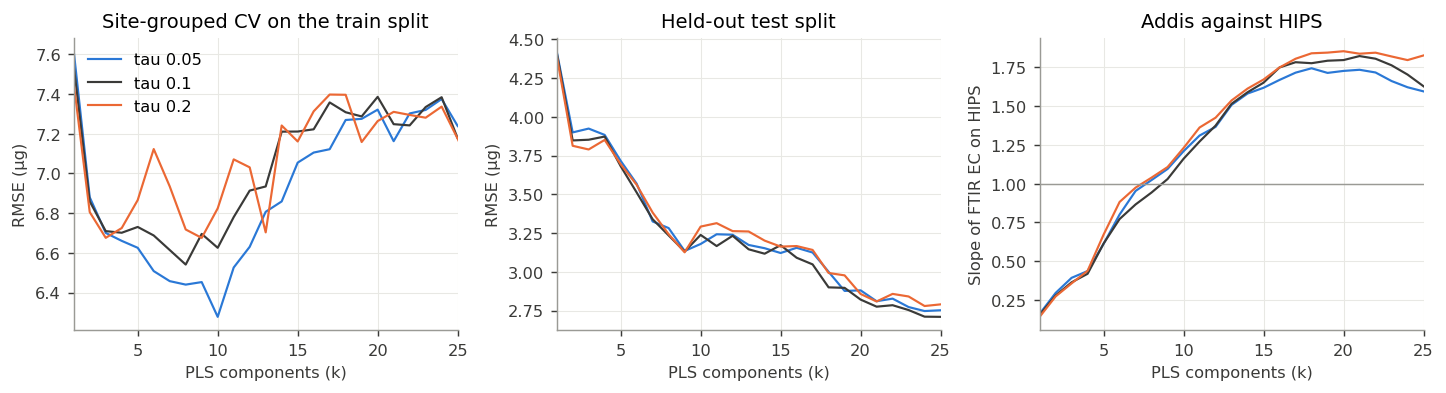

In [12]:
curves = pd.read_csv(C / "calibration_cv_curves.csv")
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.1))
for tau, color in TAU_COLOR.items():
    c = curves[curves.tau.eq(tau) & curves.training.eq("qc")]
    axes[0].plot(c.n_components, c.rmse_mean, color=color, label=f"tau {tau:g}")
    s_ = scores[scores.tau.eq(tau) & scores.training.eq("qc")]
    axes[1].plot(s_.k, s_.RMSE, color=color)
t = pd.read_csv(C / "transfer_scores.csv")
for tau, color in TAU_COLOR.items():
    axes[2].plot(t[t.tau.eq(tau)].k, t[t.tau.eq(tau)]["Addis slope vs HIPS"], color=color)
axes[2].axhline(1, color="#9a9a95", lw=.8)
axes[0].set(xlabel="PLS components (k)", ylabel="RMSE (µg)", title="Site-grouped CV on the train split", xlim=(1, 25)); axes[0].legend(frameon=False)
axes[1].set(xlabel="PLS components (k)", ylabel="RMSE (µg)", title="Held-out test split", xlim=(1, 25))
axes[2].set(xlabel="PLS components (k)", ylabel="Slope of FTIR EC on HIPS", title="Addis against HIPS", xlim=(1, 25))
fig.tight_layout(); plt.show()

Is any difference from tau 0.1 larger than chance? Sites are resampled with replacement 2,000 times and the same
filters are compared under both tau values. A negative number means the tau has the smaller error.

In [13]:
boot = pd.read_csv(C / "bootstrap.csv").rename(columns={"difference": "difference from tau 0.1 (µg)", "lo": "5 %", "hi": "95 %", "excludes_zero": "interval excludes zero"})
boot.round(3)

,score,tau,k,difference from tau 0.1 (µg),5 %,95 %,interval excludes zero
0,"Held-out test, RMSE",0.05,4,0.011,-0.074,0.109,False
1,"Held-out test, median |error|",0.05,4,0.005,-0.037,0.035,False
2,"Held-out test, RMSE",0.05,8,0.048,-0.050,0.160,False
3,"Held-out test, median |error|",0.05,8,0.011,-0.028,0.043,False
4,"Held-out test, RMSE",0.05,11,0.076,-0.024,0.209,False
5,"Held-out test, median |error|",0.05,11,0.125,0.076,0.198,True
6,"Held-out test, RMSE",0.05,18,0.100,0.027,0.171,True
7,"Held-out test, median |error|",0.05,18,0.041,-0.004,0.077,False
8,"Out-of-site, median |error|",0.05,5,-0.008,-0.023,0.012,False
9,"Out-of-site, median |error|",0.05,8,0.017,0.001,0.033,True


Out-of-site scoring over all eligible IMPROVE filters (site-grouped 5-fold) and the Addis prediction against HIPS, as in the 2 Nov transfer diagnosis.

In [14]:
t[t.k.isin([4, 5, 8, 12, 18])].pivot(index="k", columns="tau", values=["IMPROVE out-of-site median |error| (µg)", "Addis slope vs HIPS", "Addis intercept vs HIPS (µg)", "Addis R2"]).round(3)

IMPROVE out-of-site median |error| (µg)               Addis slope vs HIPS               Addis intercept vs HIPS (µg)                 Addis R2              
tau                                    0.05   0.10   0.20                0.05   0.10   0.20                         0.05    0.10    0.20     0.05   0.10   0.20
k                                                                                                                                                              
4                                     1.351  1.353  1.338               0.436  0.418  0.438                       -5.529  -5.262  -6.091    0.622  0.664  0.681
5                                     1.367  1.375  1.384               0.611  0.614  0.671                       -8.962  -8.761 -10.674    0.624  0.671  0.706
8                                     1.301  1.284  1.227               1.023  0.943  1.039                      -16.974 -14.934 -17.666    0.677  0.661  0.688
12                                    1.152  1.148  1.128               1.366  1.374  1.425                      -25.168 -25.550 -26.986    0.718  0.724  0.733
18                                    1.132  1.139  1.131               1.744  1.777  1.841                      -35.606 -36.479 -37.287    0.736  0.741  0.748

**A side finding.** The train split holds one spectrum the decision bundle marks as failing raw QC (IMPROVE filter
2008808, TONT1; its corrected absorbance spans 3.7). The 3 Nov transfer table was
made with it in training; today's harness leaves it out. With it in, this notebook's code returns the 3 Nov predictions
to 2e-8. Leaving it out moves the Addis slope at k 5 from 0.41 to 0.61, so that table's low-k rows should be reread.
The frozen k 4 model was also trained with it; section 8 measures what that does.

## 8. What the QC-failed spectrum does to network EC at k 4

The k 4 model is fitted twice on the train split of the converged tau 0.1 spectra, with and without IMPROVE filter
2008808, and both are applied to the converged network run (`qc_spectrum_effect` in
`workflows/run_vibes_tau_calibration_20261116.py`). The model with the spectrum is the 3 Nov rebuilt k 4 model (to 6e-7 µg).

**What it shows.**

- **IMPROVE cannot tell the two models apart.** Held-out RMSE is 3.850 with the spectrum and 3.873 without it.
- **SPARTAN EC is not the same.** PM2.5 EC moves by a median 17 %, and 64 % of scans move by more than 10 %. Site medians
  move from -64 % (PRFJ) to +51 % (ILHA). Addis moves 2 % at the median.
- **Field blanks drop from 1.27 to 0.30 µg.** That is closer to zero, but the blank level wanders with k for both models,
  so it does not prove the cleaned model right.
- **Nothing here picks a winner.** Without the spectrum the repeat-scan gap is larger (0.074 against 0.051 µg) and the
  Addis fit against HIPS is slightly looser (R² 0.67 against 0.71) with the same slope (0.41).
- **The spectrum is 364 times farther from the mean than a typical train spectrum.** The next most extreme train spectra
  are 19 to 33 times farther; they are very loaded filters that passed QC, and dropping one of them alone moves network
  EC by up to 6 %. Dropping 100 random spectra moves it by 0.25 % at the median.
- **The effect shrinks as k grows:** 17 % at k 4, 8 % at k 8, 3 % at k 12 and 2.5 % at k 25.

So EC from a k 4 model depends on a handful of extreme training spectra, and IMPROVE scores do not show it.

In [15]:
Q = lambda name: pd.read_csv(C / f"qc_spectrum_{name}.csv")
Q("groups").round(3)

,group,scans,median_with,median_without,median_abs_ug,median_abs_pct,moved_gt10_pct,largest_ug
0,PM2.5 scans,3626,3.760,4.331,0.747,17.198,64.009,85.836
1,Addis PM2.5 scans,274,7.876,8.057,0.457,5.310,25.547,7.479
2,PM10 scans,215,2.329,1.683,0.810,29.810,89.252,13.043
3,Field blanks,535,1.273,0.298,0.975,76.602,100.000,1.243


In [16]:
Q("checks").round(3)

,model,heldout_rmse,heldout_median_abs,heldout_bias,addis_slope,addis_intercept,addis_r2,blank_median,blank_iqr,repeat_gap,negative_share_pct,failed_spectrum_ec
0,With the spectrum,3.850,1.408,0.212,0.409,-5.540,0.712,1.273,0.003,0.051,1.103,-2.454
1,Without it,3.873,1.355,0.337,0.408,-5.228,0.671,0.298,0.004,0.074,1.544,-211.016


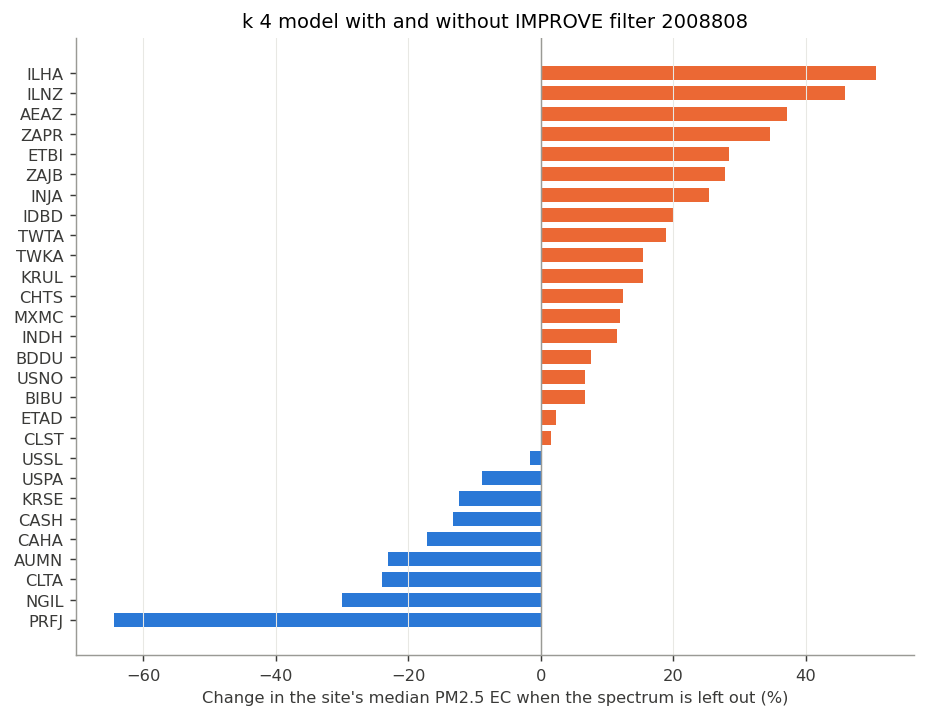

In [17]:
sites = Q("sites")
fig, ax = plt.subplots(figsize=(7.2, 5.6))
ax.barh(sites.site, sites.change_pct, color=np.where(sites.change_pct < 0, BLUE, ORANGE), height=.7)
ax.axvline(0, color="#9a9a95", lw=.8); ax.grid(axis="y", visible=False)
ax.set(xlabel="Change in the site's median PM2.5 EC when the spectrum is left out (%)", title="k 4 model with and without IMPROVE filter 2008808")
fig.tight_layout(); plt.show()

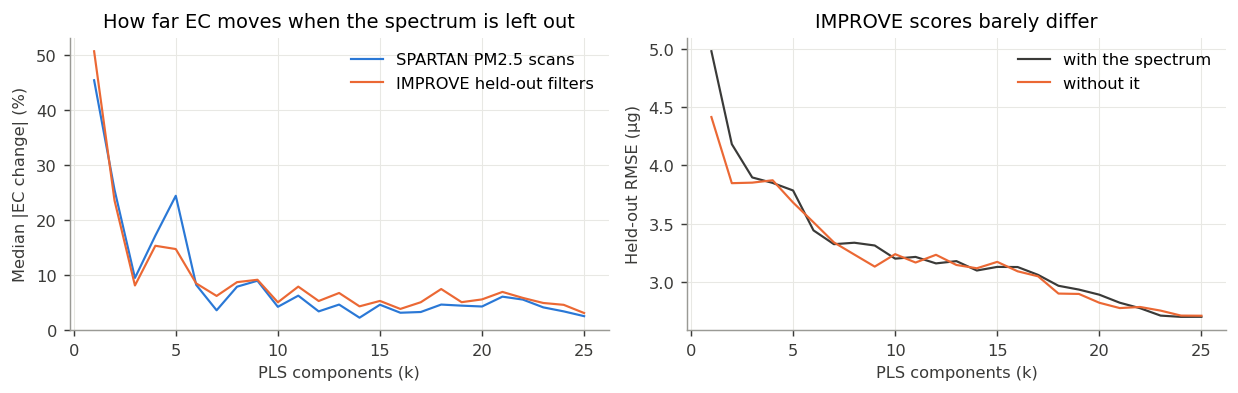

In [18]:
by_k = Q("by_k")
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.1))
axes[0].plot(by_k.k, by_k.network_median_abs_pct, color=BLUE, label="SPARTAN PM2.5 scans")
axes[0].plot(by_k.k, by_k.improve_test_median_abs_pct, color=ORANGE, label="IMPROVE held-out filters")
axes[0].set(xlabel="PLS components (k)", ylabel="Median |EC change| (%)", title="How far EC moves when the spectrum is left out", ylim=(0, None)); axes[0].legend(frameon=False)
axes[1].plot(by_k.k, by_k.heldout_rmse_with, color=INK, label="with the spectrum")
axes[1].plot(by_k.k, by_k.heldout_rmse_without, color=ORANGE, label="without it")
axes[1].set(xlabel="PLS components (k)", ylabel="Held-out RMSE (µg)", title="IMPROVE scores barely differ"); axes[1].legend(frameon=False)
fig.tight_layout(); plt.show()

The train spectra farthest from the mean spectrum. For the QC-failed one the last column is the change from leaving it out; for the others, from dropping that one spectrum from the cleaned split.

In [19]:
Q("leverage").round(2)

,filter,site,raw_qc,tor_ec_ug,distance,span,network_median_abs_pct
0,2008808,TONT1,failed,5.61,363.85,3.73,17.20
1,1851843,PHOE1,passed,89.42,32.79,1.44,3.78
2,1989644,CABI1,passed,100.67,29.85,0.59,2.53
3,1989256,LTCC1,passed,159.94,29.54,0.57,1.09
4,1967866,TOOL1,passed,393.33,23.97,0.53,6.07
5,1987819,HECA1,passed,335.25,23.75,0.69,1.82
6,1981429,YOSE1,passed,148.36,20.80,0.47,0.14
7,1989491,THSI1,passed,78.41,19.31,0.55,1.29
8,100 random spectra (median of 20 draws),NaN,passed,NaN,NaN,NaN,0.25
9,100 random spectra (largest of 20 draws),NaN,passed,NaN,NaN,NaN,4.00


## 9. Is a k 4 model trained without the heaviest filters stable on SPARTAN?

One model per training set (`training_domain_stability` in the same workflow): every QC-passed train spectrum, only those
with thermal EC below 150, 100, 50 and 25 µg, and the 99 % of spectra nearest the mean. No network PM2.5 scan reads above
50 µg and 1.5 % read above 25 µg, so the heavy training filters lie outside SPARTAN's range. Each model is tested by
dropping one of its six most extreme spectra, and by refitting on IMPROVE sites drawn with replacement 30 times.

**What it shows.**

- **One spectrum no longer matters.** The largest change from dropping one spectrum falls from 6 % (all) to 3 % (below 150 µg),
  2 % (below 50) and 0.4 % (below 25).
- **The training sites still matter.** With IMPROVE sites resampled, a scan's EC spreads by 14 % with every spectrum in and
  by 8 % below 25 µg. A site's median EC spreads by 11 % and 6 %. The worst site goes from 61 % (PRFJ) to 13 %.
- **Each cut-off gives a different EC.** The models differ from each other by a median 3 to 30 % on network scans. Addis's
  median goes from 8.1 µg (all) to 5.9 µg (below 25 µg).
- **Accuracy on light filters improves.** Held-out RMSE on IMPROVE filters below 25 µg falls from 3.04 to 2.66 µg at k 4.
- **The Addis slope against HIPS follows the cut-off as much as it follows k:** 0.41 with every spectrum, 0.23 below 25 µg
  at k 4; 1.45 and 0.72 at k 12.
- **A higher k does not remove the spread:** below 25 µg it is 7.6, 7.0 and 6.6 % at k 4, 8 and 12.

So trimming makes the model steadier, but it does not pin EC down: the cut-off is itself a choice that moves EC, and about
7 % of site-to-site resampling spread is left.

In [20]:
dom = pd.read_csv(C / "domain_policies.csv")
cols = {"training": "Training set", "train_spectra": "Train spectra", "heaviest_ug": "Heaviest (µg)", "one_spectrum_max_pct": "One spectrum, max (%)",
        "scan_spread_pct": "Scan spread (%)", "site_spread_median_pct": "Site spread, median (%)", "site_spread_max_pct": "Site spread, max (%)",
        "site_spread_max_site": "Worst site", "heldout_rmse_below25": "Held-out RMSE < 25 µg", "addis_slope": "Addis slope", "blank_median": "Blank (µg)",
        "repeat_gap": "Repeat gap (µg)", "network_median_ec": "Network median EC (µg)", "change_from_all_pct": "Change from all (%)"}
dom[dom.k.eq(4)][list(cols)].rename(columns=cols).round(2)

,Training set,Train spectra,Heaviest (µg),"One spectrum, max (%)",Scan spread (%),"Site spread, median (%)","Site spread, max (%)",Worst site,Held-out RMSE < 25 µg,Addis slope,Blank (µg),Repeat gap (µg),Network median EC (µg),Change from all (%)
0,All QC-passed,10065,393.33,6.07,13.91,10.76,61.29,PRFJ,3.04,0.41,0.30,0.07,4.33,0.00
3,EC below 150 µg,10059,148.36,2.86,14.31,10.78,33.23,PRFJ,2.94,0.45,0.65,0.07,4.43,7.89
6,EC below 100 µg,10053,93.92,2.94,11.71,8.35,33.21,AEAZ,2.88,0.42,0.67,0.06,4.42,5.66
9,EC below 50 µg,10005,49.31,1.97,9.26,7.52,18.88,AEAZ,2.71,0.30,0.93,0.06,4.43,11.62
12,EC below 25 µg,9824,25.00,0.45,7.57,5.88,12.78,ETAD,2.66,0.23,1.11,0.04,4.29,17.75
15,Nearest 99 % of spectra,9964,256.01,0.30,12.71,10.43,82.54,PRFJ,3.25,0.55,0.04,0.09,4.24,9.08


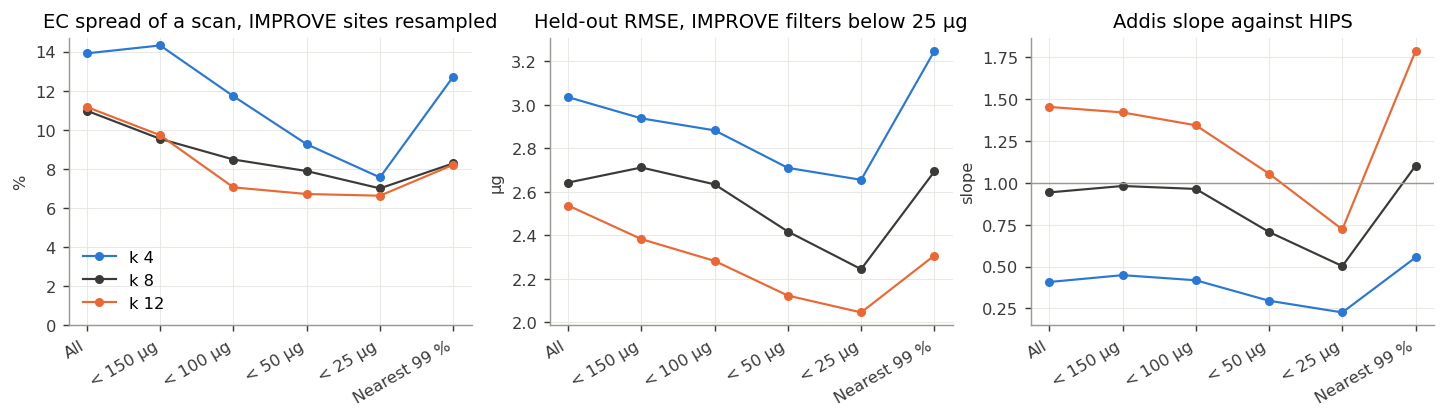

In [21]:
order = list(dom.training.drop_duplicates())
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.3))
for k, color in zip((4, 8, 12), (BLUE, INK, ORANGE)):
    d_ = dom[dom.k.eq(k)].set_index("training").loc[order]
    axes[0].plot(range(len(order)), d_.scan_spread_pct, marker="o", ms=4, color=color, label=f"k {k}")
    axes[1].plot(range(len(order)), d_.heldout_rmse_below25, marker="o", ms=4, color=color)
    axes[2].plot(range(len(order)), d_.addis_slope, marker="o", ms=4, color=color)
short = [o.replace("EC below ", "< ").replace("All QC-passed", "All").replace("Nearest 99 % of spectra", "Nearest 99 %") for o in order]
for ax, title, label in zip(axes, ("EC spread of a scan, IMPROVE sites resampled", "Held-out RMSE, IMPROVE filters below 25 µg", "Addis slope against HIPS"), ("%", "µg", "slope")):
    ax.set_xticks(range(len(order)), short, rotation=30, ha="right"); ax.set(title=title, ylabel=label)
axes[2].axhline(1, color="#9a9a95", lw=.8); axes[0].set_ylim(0, None); axes[0].legend(frameon=False)
fig.tight_layout(); plt.show()

How far two training sets' network PM2.5 EC differ at k 4 (median |difference|, percent of the row's EC).

In [22]:
pairs_ = pd.read_csv(C / "domain_pairs.csv")
pairs_[pairs_.k.eq(4)].pivot(index="training", columns="against", values="median_abs_pct").loc[order, order].round(1)

against,All QC-passed,EC below 150 µg,EC below 100 µg,EC below 50 µg,EC below 25 µg,Nearest 99 % of spectra
training,,,,,,
All QC-passed,0.0,7.9,5.7,11.6,17.7,9.1
EC below 150 µg,7.8,0.0,2.7,12.3,19.2,11.0
EC below 100 µg,5.9,2.7,0.0,9.8,16.8,12.5
EC below 50 µg,13.2,13.2,10.5,0.0,7.4,21.1
EC below 25 µg,21.8,22.0,19.3,7.9,0.0,29.9
Nearest 99 % of spectra,8.7,10.1,11.3,17.9,23.7,0.0


In [23]:
ds = pd.read_csv(C / "domain_sites.csv")
ds.pivot(index="site", columns="training", values="median_ec")[order].round(2)

training,All QC-passed,EC below 150 µg,EC below 100 µg,EC below 50 µg,EC below 25 µg,Nearest 99 % of spectra
site,,,,,,
AEAZ,2.66,3.62,3.66,4.57,5.24,3.25
AUMN,1.90,2.11,2.13,2.17,2.15,2.15
BDDU,6.95,7.68,7.32,6.23,5.54,8.21
BIBU,12.53,13.07,12.56,10.38,8.99,14.80
CAHA,2.00,2.34,2.29,2.33,2.32,1.99
CASH,2.63,3.06,3.02,2.91,2.75,2.78
CHTS,7.07,7.24,7.13,6.81,6.34,6.68
CLST,5.56,5.90,5.79,5.16,4.58,6.01
CLTA,2.03,2.42,2.37,2.34,2.28,2.14


## 10. Does the Addis slope still follow k once the training set is held fixed?

Earlier work read the Addis slope of FTIR EC on HIPS BC as following the number of PLS components. Section 9 showed the
slope also moves with the training set, so the earlier reading is repeated here with the training set held fixed
(`addis_by_training_set`): one model per k 1 to 25 for each of the six sets, applied to the 233 Addis spectra. The band
is the 5th to 95th percentile over 30 refits on IMPROVE sites drawn with replacement.

**What it shows.**

- **The slope follows k under every training set.** It rises about fivefold from k 4 to k 18 with every spectrum in
  (0.41 to 2.11) and three and a half fold below 25 µg (0.23 to 0.81). The intercept falls with it.
- **The training set moves it too, at every k.** Below 25 µg the slope is 0.38 to 0.56 of the slope with every spectrum
  in, and it never reaches 1. Below 50 µg it reaches 1 at k 11; the other four sets reach it at k 8 or 9.
- **Cut-offs of 150 and 100 µg are not distinguishable from "all".** From k 2 up they stay inside the band that
  resampling IMPROVE sites draws around it (0.29 to 0.61 at k 4, 1.16 to 1.72 at k 12).
- **The training sites alone move the slope by 20 to 50 %** (the width of that band).
- **R² does not choose.** It stays between 0.60 and 0.78 from k 3 up under every set. k and the training set change the
  scale of Addis EC (median 8.1 µg at k 4 and 18.0 µg at k 12 with every spectrum in; 5.9 and 13.0 µg below 25 µg), not
  how closely it follows HIPS.

So "the k that matches HIPS" is not a property of k alone. HIPS reads low on dark filters, so a slope of 1 is a
comparison, not a target.

In [24]:
dk = pd.read_csv(C / "domain_addis_by_k.csv")
show = dk[dk.k.isin([4, 8, 12, 18])].assign(slope=lambda f: f.addis_slope.round(2).astype(str) + " (" + f.slope_lo.round(2).astype(str) + " to " + f.slope_hi.round(2).astype(str) + ")")
show.pivot(index="training", columns="k", values="slope").loc[order].rename(columns=lambda k: f"Slope at k {k} (5th to 95th pct)")

k,Slope at k 4 (5th to 95th pct),Slope at k 8 (5th to 95th pct),Slope at k 12 (5th to 95th pct),Slope at k 18 (5th to 95th pct)
training,,,,
All QC-passed,0.41 (0.29 to 0.61),0.94 (0.64 to 1.15),1.45 (1.16 to 1.72),2.11 (1.56 to 2.5)
EC below 150 µg,0.45 (0.27 to 0.69),0.98 (0.65 to 1.17),1.42 (1.05 to 1.63),1.84 (1.38 to 2.12)
EC below 100 µg,0.42 (0.3 to 0.56),0.96 (0.77 to 1.13),1.34 (1.12 to 1.51),1.68 (1.33 to 1.87)
EC below 50 µg,0.3 (0.25 to 0.39),0.71 (0.6 to 0.89),1.05 (0.87 to 1.28),1.2 (0.99 to 1.4)
EC below 25 µg,0.23 (0.18 to 0.31),0.5 (0.36 to 0.58),0.72 (0.6 to 0.85),0.81 (0.61 to 0.91)
Nearest 99 % of spectra,0.55 (0.37 to 0.71),1.1 (0.78 to 1.25),1.79 (1.46 to 1.99),2.05 (1.7 to 2.4)


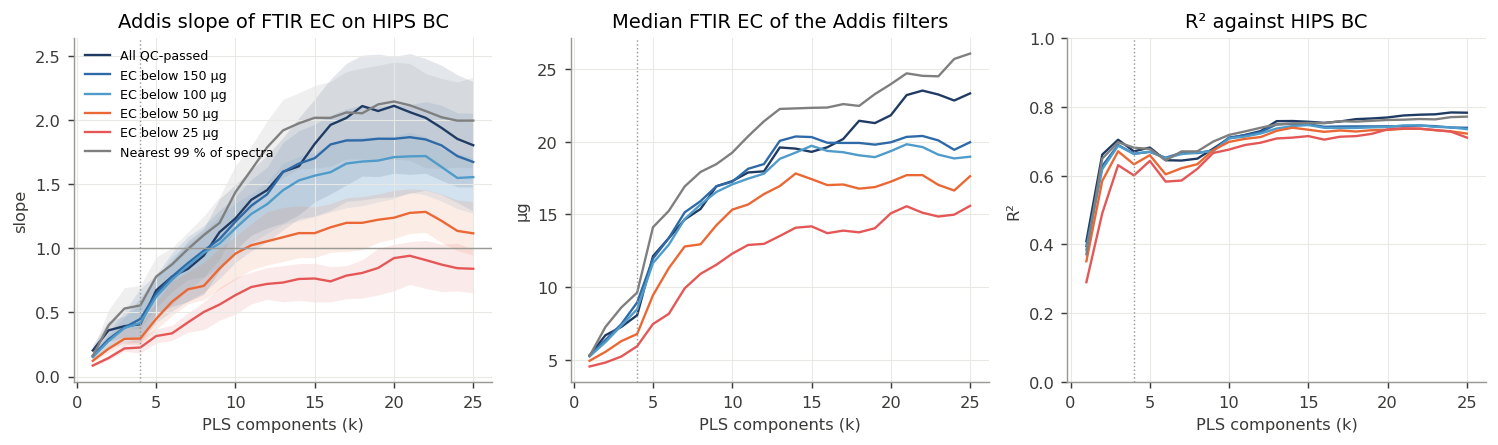

In [25]:
shades = dict(zip(order, ("#1f3b63", "#2f6aa8", "#4f9bc9", ORANGE, "#e45756", "#7f7f7f")))
fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.5))
for name in order:
    d_ = dk[dk.training.eq(name)]
    axes[0].fill_between(d_.k, d_.slope_lo, d_.slope_hi, color=shades[name], alpha=.12, lw=0)
    axes[0].plot(d_.k, d_.addis_slope, color=shades[name], lw=1.3, label=name)
    axes[1].plot(d_.k, d_.addis_median_ec, color=shades[name], lw=1.3)
    axes[2].plot(d_.k, d_.addis_r2, color=shades[name], lw=1.3)
axes[0].axhline(1, color="#9a9a95", lw=.8)
for ax, title, label in zip(axes, ("Addis slope of FTIR EC on HIPS BC", "Median FTIR EC of the Addis filters", "R² against HIPS BC"), ("slope", "µg", "R²")):
    ax.axvline(4, color="#9a9a95", lw=.8, ls=":"); ax.set(title=title, xlabel="PLS components (k)", ylabel=label)
axes[2].set_ylim(0, 1); axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); plt.show()

In [26]:
ratio = dk.pivot(index="k", columns="training", values="addis_slope")
reach = {name: (int(ratio.index[(ratio[name] >= 1).to_numpy().argmax()]) if (ratio[name] >= 1).any() else None) for name in order}
pd.DataFrame({"First k with slope of at least 1": reach,
              "Slope relative to all, smallest over k": (ratio[order].div(ratio["All QC-passed"], axis=0)).min().round(2),
              "largest over k": (ratio[order].div(ratio["All QC-passed"], axis=0)).max().round(2)})

,First k with slope of at least 1,"Slope relative to all, smallest over k",largest over k
All QC-passed,9.0,1.00,1.00
EC below 150 µg,9.0,0.80,1.10
EC below 100 µg,9.0,0.75,1.03
EC below 50 µg,11.0,0.57,0.81
EC below 25 µg,NaN,0.38,0.56
Nearest 99 % of spectra,8.0,0.79,1.36


## 11. What to do with it

1. **Keep the frozen model as it is for now.** A trimmed training set is steadier and more accurate on light IMPROVE
   filters, but it lowers Addis EC by about a quarter and halves the Addis slope, and nothing measured here says the
   lower reading is more correct. That needs a reference SPARTAN does not have yet (thermal EC on SPARTAN filters).
2. **Quote EC from this calibration with a spread.** The table below is the spread to quote for a site's median EC from
   the k 4 model with every QC-passed spectrum in: the standard deviation over refits on resampled IMPROVE sites. It is
   under 10 % at 12 of 28 sites, 10 to 20 % at 13, and above 20 % at PRFJ, AEAZ and ILHA. It does not include the choice
   of k or of training set, which move EC by more.
3. **The training set and k are one decision, for Ann and Satoshi.** Both move the Addis comparison with HIPS, so a
   result of the form "the slope follows k" holds only for a stated training set (`docs/open-items.md`).

In [27]:
spread = ds[ds.training.eq("All QC-passed")].set_index("site")[["median_ec", "spread_pct"]]
spread = spread.assign(spread_ug=spread.median_ec * spread.spread_pct / 100).sort_values("spread_pct", ascending=False)
print((spread.spread_pct < 10).sum(), "sites under 10 %,", spread.spread_pct.between(10, 20).sum(), "between 10 and 20 %,", (spread.spread_pct > 20).sum(), "above 20 %")
spread.rename(columns={"median_ec": "Median EC (µg)", "spread_pct": "Spread (%)", "spread_ug": "Spread (µg)"}).round(2)

12 sites under 10 %, 13 between 10 and 20 %, 3 above 20 %


,Median EC (µg),Spread (%),Spread (µg)
site,,,
PRFJ,0.54,61.29,0.33
AEAZ,2.66,40.33,1.07
ILHA,2.93,22.30,0.65
ILNZ,3.72,19.54,0.73
NGIL,3.75,19.38,0.73
ETAD,8.06,17.74,1.43
KRSE,6.15,16.93,1.04
BDDU,6.95,15.50,1.08
CLTA,2.03,14.68,0.30
